In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

In [6]:
def creategraph(G,plant):
   protein_csv = f"dataset/datacsv/{plant}.csv" 
   protein_scores_csv = f"{plant}.csv"

   proteins = pd.read_csv(protein_csv)
   score_data = pd.read_csv(protein_scores_csv)
   G.add_nodes_from(proteins['Proteins'].tolist())
   edges = []
   for row in score_data.itertuples():
      edges.append((row.Protein1,row.Protein2,row.Score))
   G.add_weighted_edges_from(edges)
   

In [7]:
def draw_clusters(G, clusters, title):
    plt.figure(figsize=(6, 5))
    pos = nx.spring_layout(G, seed=42)
    colors = plt.cm.tab10.colors

    for i, cluster in enumerate(clusters):
        nx.draw_networkx_nodes(G, pos,
                               nodelist=cluster,
                               node_color=[colors[i % len(colors)]],
                               label=f"Cluster {i+1}",
                               node_size=20 )
    nx.draw_networkx_edges(G, pos, alpha=0.3)
    plt.title(title)
    plt.legend()
    plt.axis("off")
    plt.show()

In [8]:
import igraph as ig
import leidenalg

def nx_to_igraph(G):
    mapping = {node: idx for idx, node in enumerate(G.nodes())}
    G_ig = ig.Graph()
    G_ig.add_vertices(len(mapping))
    edges = [(mapping[u], mapping[v]) for u, v in G.edges()]
    G_ig.add_edges(edges)

    if nx.get_edge_attributes(G, 'weight'):
        weights = [G[u][v].get('weight', 1.0) for u, v in G.edges()]
        G_ig.es['weight'] = weights

    return G_ig, mapping

def leiden_clustering(G):
    G_ig, mapping = nx_to_igraph(G)
    partition = leidenalg.find_partition(G_ig, leidenalg.ModularityVertexPartition)
    clusters = [list(comm) for comm in partition]
    reverse_mapping = {v: k for k, v in mapping.items()}
    clusters_named = [[reverse_mapping[node] for node in cluster] for cluster in clusters]
    return clusters_named

In [9]:
def createncluster(plant):
    print("Creating Graph")
    G = nx.Graph()
    creategraph(G,plant)
    print("Graph created")
    clusters_leiden = leiden_clustering(G)
    draw_clusters(G,clusters_leiden,plant)
    return clusters_leiden


Creating Graph
Graph created


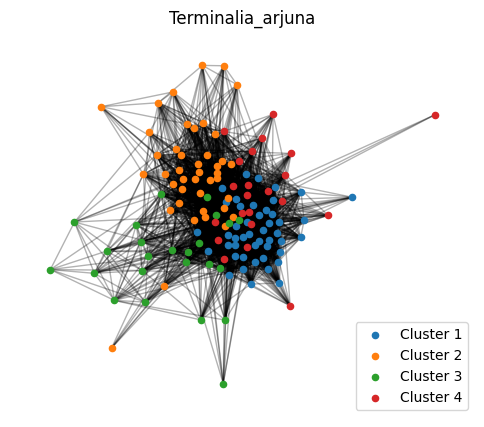

['TYR', 'CASP9', 'CASP8', 'CASP7', 'CSNK2A1', 'MMP2', 'CCL2', 'PRKCB', 'PRKACA', 'SYK', 'PARG', 'PRKCA', 'KEAP1', 'MAPK1', 'SERPINE1', 'CCND1', 'CCNB1', 'CDK4', 'CDK2', 'TNFRSF10B', 'NOTCH1', 'MITF', 'MAP2K1', 'DDIT4', 'NFKBIB', 'PKM', 'GSK3B', 'MAPK8', 'MCL1', 'MMP9', 'PLAU', 'CDK1', 'NFE2L2', 'ABCC1', 'RELA', 'SRC', 'AFP', 'TGFB1', 'PTK2', 'TLR4', 'NFAT5', 'NAMPT', 'HMGB1', 'TOP1', 'TOP2A', 'ICAM1']
['DHDH', 'AKR1C4', 'LRTOMT', 'SULT1C2', 'SULT1A2', 'SULT1A3', 'COMT', 'AKR1C1', 'GCG', 'SQLE', 'PGD', 'NR1I3', 'G6PD', 'CYP1B1', 'TP53', 'AKT1', 'HSD11B2', 'NR1I2', 'CYP3A4', 'UGT2B15', 'CYP1A2', 'CYP1A1', 'PCK2', 'DAO', 'AMFR', 'PCK1', 'ME2', 'UBE2G2', 'HOGA1', 'HAO1', 'HMOX1', 'SI', 'PPARA', 'UGT2B10', 'UGT2B11', 'ABCG5', 'ABCB11', 'ABCG8', 'CYP7A1', 'SREBF1', 'SREBF2', 'DHCR24']
['LPO', 'LCN2', 'CASP3', 'HBB', 'CA12', 'CA1', 'TMPRSS11D', 'CA2', 'CA3', 'CA5A', 'CA5B', 'CA7', 'CA14', 'CA6', 'CA9', 'CFTR', 'INS', 'IL6', 'S100A7', 'LTF', 'PC', 'TF', 'LDHA', 'ANO1']
['MPO', 'EPX', 'PRDX5', 

In [10]:
clusters = createncluster("Terminalia_arjuna")
for i in clusters:
    print(i)

Creating Graph
Graph created


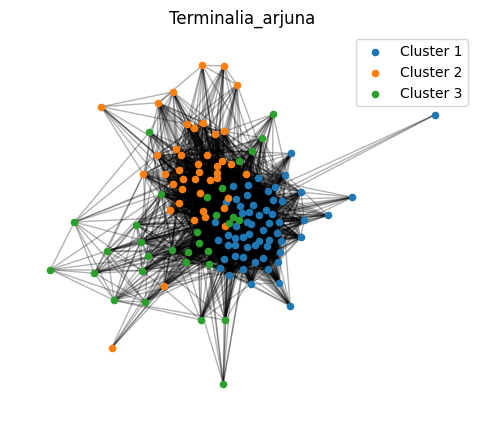

['MPO', 'EPX', 'LCN2', 'PLA2G1B', 'CASP9', 'CASP8', 'CASP7', 'CSNK2A1', 'MMP2', 'RETN', 'CCL2', 'NOS3', 'PRKCB', 'PRKACA', 'SYK', 'PARG', 'PRKCA', 'KEAP1', 'MAPK1', 'SERPINE1', 'NFKB1', 'CCND1', 'ALOX12', 'CCNB1', 'CDK4', 'MAPK3', 'CDK2', 'TNFRSF10B', 'NOTCH1', 'ALOX15', 'MITF', 'MAP2K1', 'DDIT4', 'NFKBIB', 'GSK3B', 'NOS2', 'NOS1', 'MAPK8', 'PTGS1', 'PTGS2', 'MCL1', 'MMP9', 'PLAU', 'CDK1', 'NFE2L2', 'RELA', 'SRC', 'TGFB1', 'KCNT2', 'PTK2', 'TLR4', 'NFAT5', 'SLC2A4', 'NAMPT', 'PTGIR', 'HMGB1', 'TOP1', 'TOP2A', 'APOE', 'ICAM1']
['DHDH', 'AKR1C4', 'LRTOMT', 'SULT1C2', 'SULT1A2', 'SULT1A3', 'COMT', 'AKR1C1', 'GCG', 'SQLE', 'PGD', 'NR1I3', 'G6PD', 'CYP1B1', 'AKT1', 'HSD11B2', 'NR1I2', 'CYP3A4', 'UGT2B15', 'CYP1A2', 'CYP1A1', 'ABCC1', 'PCK2', 'DAO', 'CAT', 'AMFR', 'PCK1', 'UBE2G2', 'HOGA1', 'HAO1', 'HMOX1', 'SI', 'PPARA', 'UGT2B10', 'UGT2B11', 'ABCG5', 'ABCB11', 'ABCG8', 'CYP7A1', 'SREBF1', 'SREBF2', 'DHCR24']
['LPO', 'TYR', 'PRDX5', 'HMBS', 'CASP3', 'HBB', 'CA12', 'CA1', 'TMPRSS11D', 'CA2',

In [9]:
clusters = createncluster("Terminalia_arjuna")
for i in clusters:
    print(i)

Creating Graph
Graph created


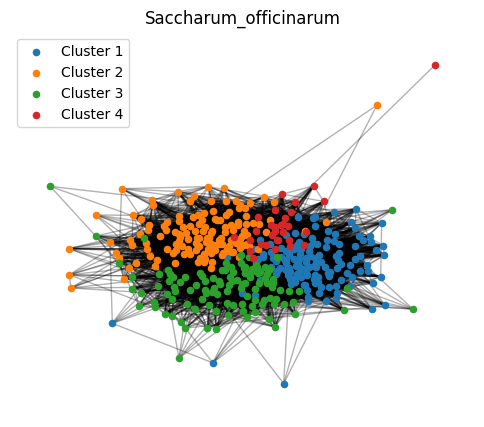

['ACP5', 'ACPP', 'ENPP1', 'CEACAM1', 'SIRT1', 'NFKBIA', 'MMP2', 'CASP14', 'HAMP', 'CCL2', 'CCND1', 'IL5', 'FGF23', 'TNFSF11', 'IL6', 'TLR2', 'REN', 'ACKR2', 'IL9', 'PTH', 'IL15', 'SOST', 'LPL', 'CASP3', 'LEP', 'ADIPOQ', 'TSLP', 'CTSL', 'CCR9', 'TLR9', 'BGLAP', 'NGF', 'RUNX2', 'MMP9', 'TLR4', 'ALPL', 'KL', 'S100G', 'IRF4', 'IGFBP3', 'ALPP', 'SPP1', 'IL10', 'GC', 'CAMP', 'LTF', 'TMPRSS11D', 'GBA', 'SFTPD', 'TF', 'NEUROG3', 'TYR', 'ERVFRD-1', 'MIF', 'MPO', 'ALOX15', 'ALOX5', 'EPX', 'LPO', 'TPO', 'COMP', 'INS', 'FABP2', 'PAEP', 'LY96', 'PPARG', 'ALB', 'PCSK1', 'HNF4A', 'THBS4', 'INS-IGF2', 'GM2A', 'THBS3', 'FFAR4', 'APOM', 'GCG', 'PVR', 'MSR1', 'CCL16', 'HPRT1', 'PCSK2', 'FURIN', 'LCN2', 'PCSK6', 'MBOAT4', 'PCSK7', 'NOS2', 'PCSK5', 'CPA1', 'PILRA', 'NOD1', 'C8G', 'CMA1', 'PMP2', 'FABP4', 'FST', 'GDF11', 'MSTN', 'SERPINA10', 'PARP12', 'BCL2A1', 'CPB1', 'ACE', 'CELA1', 'DTX3L', 'FABP5', 'CLEC4E', 'GREM1', 'RNASE3', 'F2', 'ADAM17', 'GREM2', 'CA13', 'EBF1', 'BGN', 'SERPINA5', 'ANG', 'KLK5', 'R

In [22]:
clusters = createncluster("Saccharum_officinarum")
for i in clusters:
    print(i)

Creating Graph
Graph created


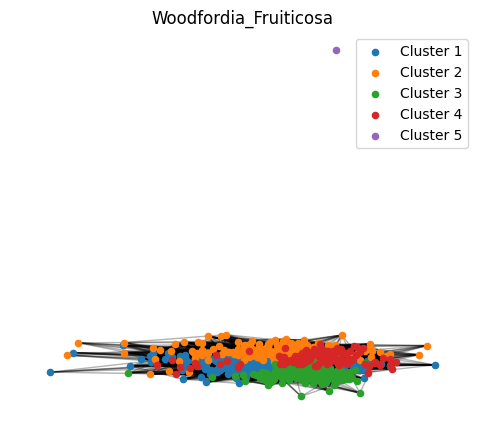

['MME', 'CD83', 'ESR1', 'MAPK1', 'HMOX1', 'NFKBIA', 'MMP2', 'CCL2', 'STAT3', 'CDK2', 'RB1', 'IGF1R', 'TP53', 'ATM', 'ITGA2', 'CSF2', 'TNFRSF11B', 'CASP3', 'MMP1', 'NOS2', 'CASP9', 'PTGES', 'ESR2', 'SRC', 'STAT1', 'CHUK', 'JUN', 'RPS6KA3', 'CDK1', 'IGF2', 'CA12', 'CSNK2A1', 'RETN', 'IL4', 'TYR', 'NOS3', 'PRKCB', 'SYK', 'CA9', 'PARG', 'PRKCA', 'TBX21', 'SIRT1', 'CASP14', 'GSK3A', 'SERPINE1', 'VIM', 'SPI1', 'CCND1', 'CDKN1B', 'MLH1', 'IL1R1', 'TNFSF11', 'FLT3', 'BHLHE41', 'CDKN1A', 'HSPB1', 'JAG1', 'ANXA1', 'TLR2', 'MMP13', 'AXIN1', 'XRCC1', 'IL1A', 'TYRO3', 'DNMT3A', 'EGF', 'CDH2', 'ERBB2', 'EGFR', 'TNFRSF10B', 'APP', 'WIF1', 'BAX', 'MGMT', 'BCL2L1', 'IGF1', 'HSPB3', 'IL13', 'AOC3', 'BID', 'GSK3B', 'DNMT3B', 'SOCS1', 'RARB', 'SMAD3', 'LAMP1', 'ENOX2', 'HIF1A', 'SNCA', 'CAV1', 'HMGB1', 'CTNNB1', 'COL18A1', 'CASP8', 'DNMT1', 'MAPK8', 'PARP1', 'CASP7', 'MMP9', 'TLR4', 'COL15A1', 'IRS2', 'ID1', 'BMI1', 'RECK', 'AKTIP', 'NFE2L2', 'DYRK1A', 'ACAN', 'CLK1', 'CDKN2A', 'NFAT5', 'MUC5AC', 'ITGAM',

In [23]:
clusters = createncluster("Woodfordia_Fruiticosa")
for i in clusters:
    print(i)

In [24]:
sum=0
for i in clusters:
    sum+=len(i)
print(sum)

726
